In [1]:
# Load the context-length scores of every model
import glob
import json
import os

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

DATA_FILE = "tep_sp_spaced_6min_noisy.h5"   # dataset to compare
DATA_STEM = os.path.splitext(DATA_FILE)[0]
RESULTS_PATTERN = f"Results/Context_setpointforecast_*_{DATA_STEM}.h5"
METRICS = ["scaled MAE", "MAPE (%)", "coverage", "scaled Winkler"]

scores, settings = {}, {}
for fn in sorted(glob.glob(RESULTS_PATTERN)):
    with h5py.File(fn, "r") as f:
        model = f.attrs["model"]
        settings[model] = json.loads(f.attrs["settings"])
        contexts = [c.decode() if isinstance(c, bytes) else str(c) for c in f["context"][()]]
        table = pd.DataFrame({m: f[f"average/{m}"][()] for m in METRICS}, index=pd.Index(contexts, name="context"))
        table.insert(0, "context used", f["context_used"][()])
        table.attrs["events"] = list(f["event"][()])
        scores[model] = table
MODELS = list(scores)
if not MODELS:
    raise FileNotFoundError(f"No results match {RESULTS_PATTERN}, run the Context notebooks on {DATA_FILE} first")
for key in ["data_file", "excluded_events", "covariates"]:
    if len({str(settings[m][key]) for m in MODELS}) > 1:
        raise ValueError(f"The models differ in {key}, run them with the same settings first")
print(f"Loaded {', '.join(MODELS)} ({settings[MODELS[0]]['data_file']}, "
      f"events {', '.join(map(str, scores[MODELS[0]].attrs['events']))})")

Loaded Chronos-2, TimesFM 3.0 (tep_sp_spaced_6min_noisy.h5, events 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76)


In [2]:
# Scores per context length, averaged over the test events
pd.concat(scores, axis=1).round(3)

Chronos-2                                              TimesFM 3.0  \
        context used scaled MAE MAPE (%) coverage scaled Winkler context used   
context                                                                         
max           6225.0      0.514    2.248    0.812          2.304       6225.0   
5000          5000.0      0.513    2.238    0.816          2.298       5000.0   
4000          4000.0      0.514    2.237    0.811          2.301       4000.0   
3000          3000.0      0.529    2.313    0.806          2.398       3000.0   
2000          2000.0      0.536    2.352    0.808          2.436       2000.0   
1000          1000.0      0.568    2.540    0.777          2.673       1000.0   
500            500.0      0.602    2.696    0.749          2.871        500.0   
250            250.0      0.631    2.859    0.735          3.108        250.0   

                                                     
        scaled MAE MAPE (%) coverage scaled Winkler  
context                                              
max          0.557    2.458    0.830          2.449  
5000         0.556    2.454    0.847          2.473  
4000         0.563    2.481    0.853          2.512  
3000         0.568    2.510    0.851          2.556  
2000         0.572    2.547    0.863          2.643  
1000         0.592    2.653    0.853          2.782  
500          0.616    2.793    0.847          2.993  
250          0.654    2.961    0.865          3.240

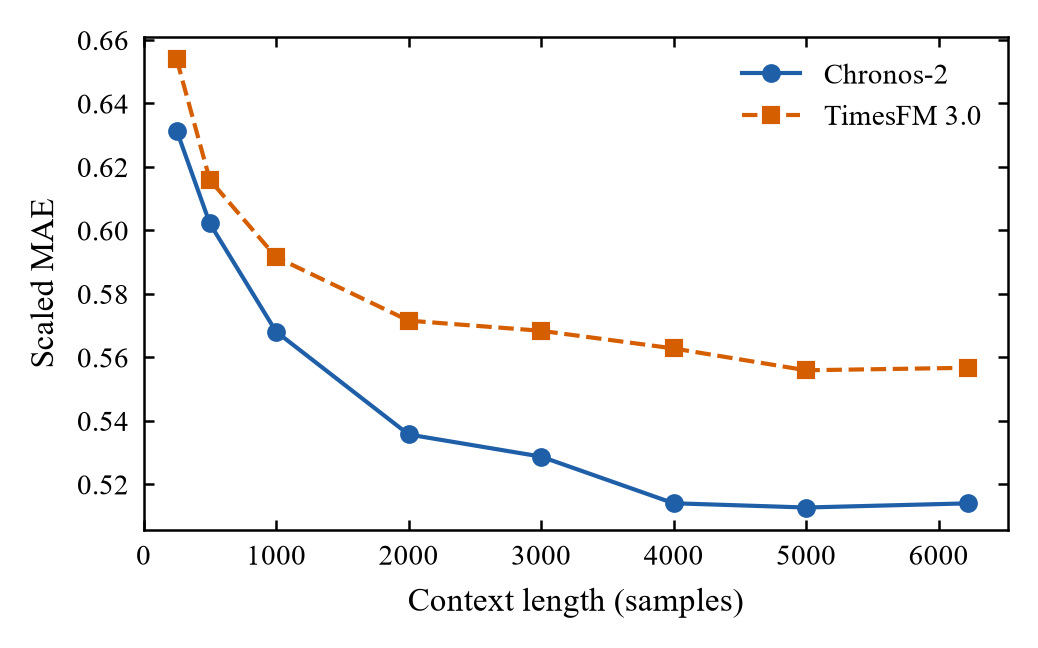

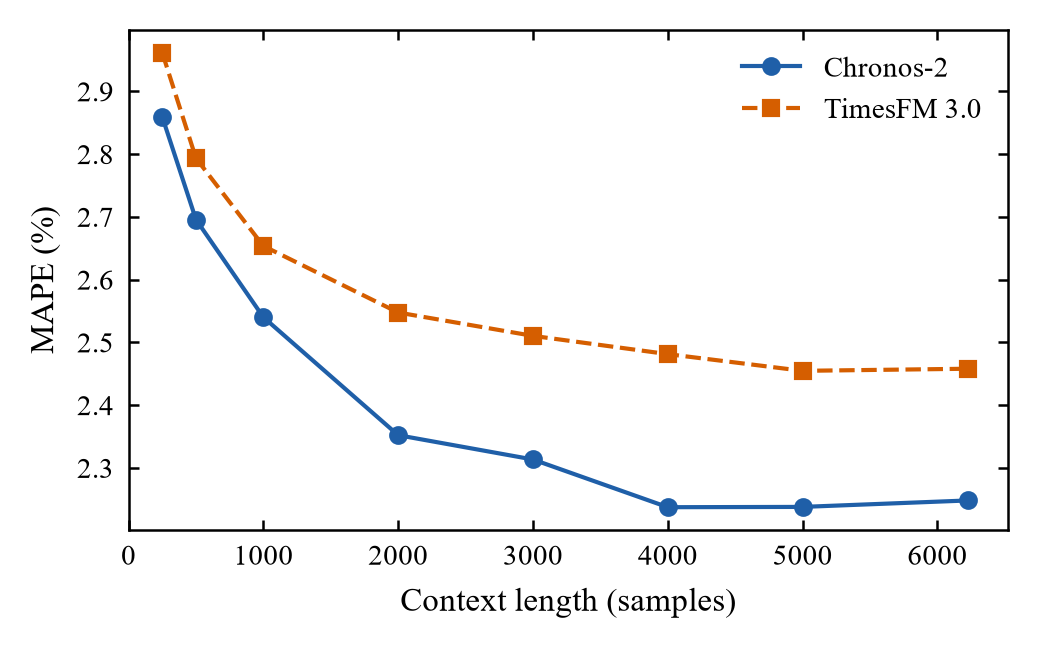

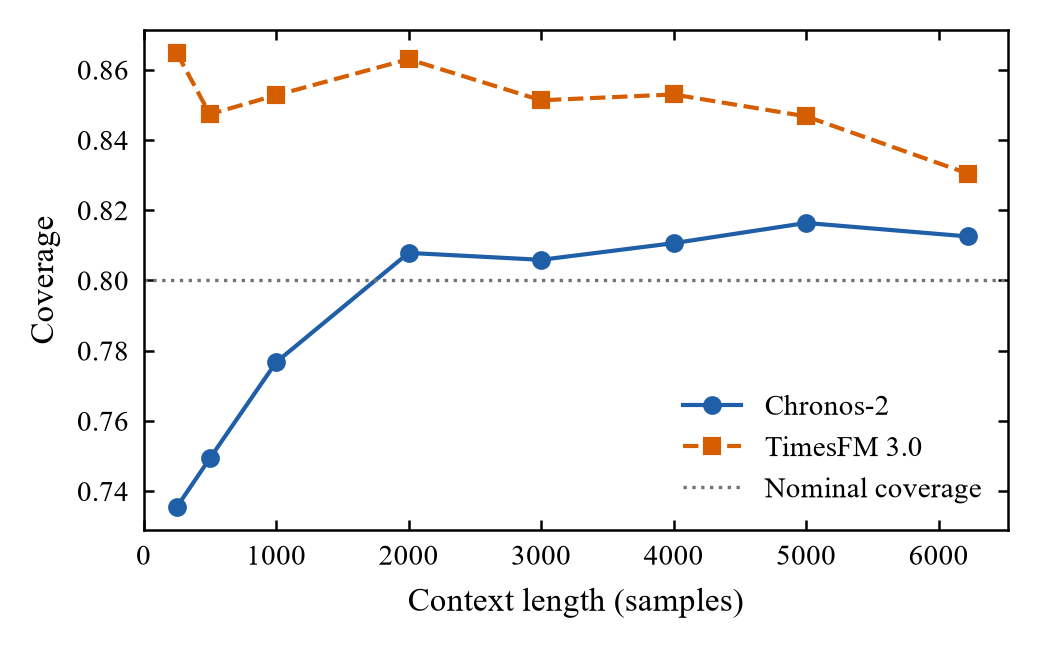

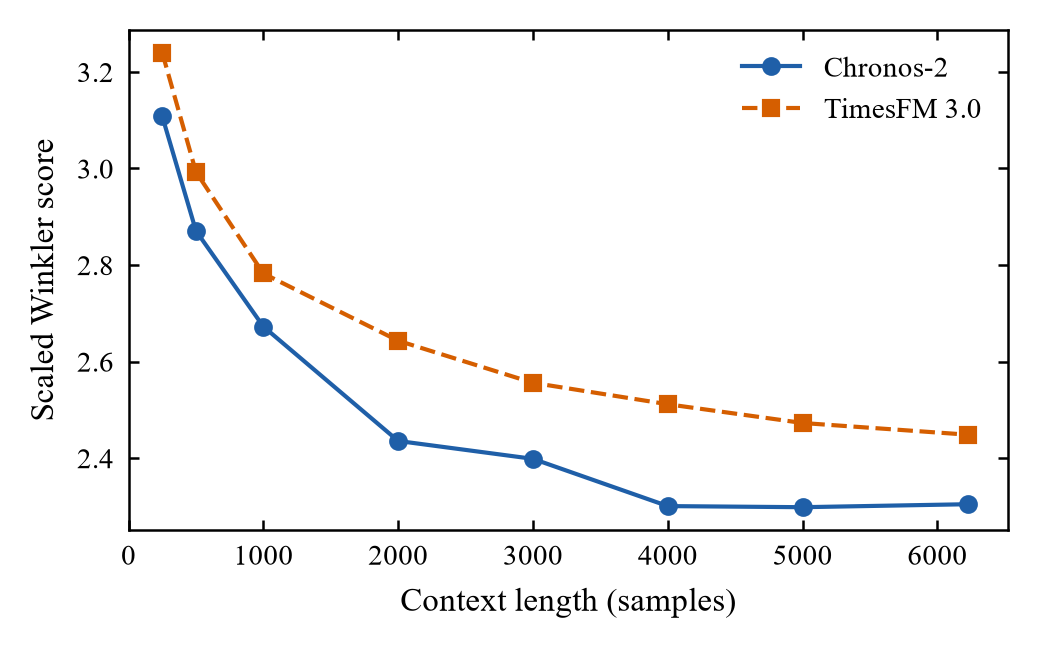

Saved Figures/Context_scaled_MAE_tep_sp_spaced_6min_noisy, Figures/Context_MAPE_tep_sp_spaced_6min_noisy, Figures/Context_coverage_tep_sp_spaced_6min_noisy, Figures/Context_scaled_Winkler_tep_sp_spaced_6min_noisy (.pdf and .png)


In [3]:
# Article figures: one metric against context length per figure
FIGURE_DIR = "Figures"
ARTICLE_COLORS = ["#1f5fa8", "#d55e00", "#009e73", "#cc79a7"]   # same colours as the forecast figures
ARTICLE_MARKERS = ["o", "s", "^", "D"]
ARTICLE_LINESTYLES = ["-", "--", "-.", ":"]
COVERAGE_TARGET = 0.8
YLABELS = {"scaled MAE": "Scaled MAE", "MAPE (%)": "MAPE (%)", "coverage": "Coverage",
           "scaled Winkler": "Scaled Winkler score"}
ARTICLE_STYLE = {
    "figure.dpi": 300,   # sharp figures in the notebook, the saved files use dpi=600
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
}

os.makedirs(FIGURE_DIR, exist_ok=True)
for metric in METRICS:
    with plt.rc_context(ARTICLE_STYLE):
        fig, ax = plt.subplots(figsize=(3.5, 2.2))
        for model, color, marker, ls in zip(MODELS, ARTICLE_COLORS, ARTICLE_MARKERS, ARTICLE_LINESTYLES):
            table = scores[model].sort_values("context used")
            ax.plot(table["context used"], table[metric], color=color, ls=ls, lw=1.0, marker=marker, ms=3.5,
                    label=model)
        if metric == "coverage":
            ax.axhline(COVERAGE_TARGET, color="0.45", ls=":", lw=0.8, label="Nominal coverage")
        ax.set_xlabel("Context length (samples)")
        ax.set_ylabel(YLABELS[metric])
        ax.set_xlim(left=0)
        ax.legend(frameon=False, loc="best")
        fig.tight_layout()
        slug = metric.split(" (")[0].replace(" ", "_")
        for ext in ["pdf", "png"]:
            fig.savefig(f"{FIGURE_DIR}/Context_{slug}_{DATA_STEM}.{ext}", dpi=600, bbox_inches="tight")
        plt.show()
print(f"Saved {', '.join(f'{FIGURE_DIR}/Context_' + m.split(' (')[0].replace(' ', '_') + f'_{DATA_STEM}' for m in METRICS)} (.pdf and .png)")